# DATA-445: Homework Assignment 8

**Instructions**

- This homework assignment is worth **88** points.
- Please submit a **.ipynb** file to Blackboard.
- **Please strive for clarity and organization.**
- **AI usage**:
  - AI use is strictly **prohibited** for conceptual exercises.
  - For applied (Python) exercises, you may use AI exclusively for **debugging**. Do not use AI to generate answers.
- **Due Date: November 13, 2026, by 11:59 PM.**

## Exercise 1 (9 points)

Principal component analysis (PCA) and linear discriminant analysis (LDA) are both linear techniques for dimensionality reduction.

**(a)** In your own words, state what objective each method optimizes, and explain why PCA is called *unsupervised* while LDA is called *supervised*.

**(b)** Describe a situation in which PCA would discard exactly the information that is most useful for classification, while LDA would keep it.

**(c)** For a classification problem with $c$ classes and $d$ features ($d > c$), what is the maximum number of linear discriminants LDA can produce? Explain why.

*Write your answer here.*
 - A. PCA maximizes the amount of variance in the data while reducing the number of dimensions. It is unsupervised because it does not use class labels. LDA maximizes the separation between different classes while minimizing variation. it is supervised because it uses known class labels.
 - B. A dataset where two groups are classified based on a small difference in income, but the age gap is large. PCA could focus on age because it has more variation, ignorning income, which is more useful for separating the groups. LDA would prioritize income because it distinguishes the classes.
 - C. The max number of linear discriminants LDA can produce is c - 1, where c is # of classes, because LDA focuses on separating classes, and there can only be c - 1 independent directions of separation, regardless of the amount of features available.

## Exercise 2 (5 points)

Which of the following statements about nonlinear dimensionality reduction (t-SNE and UMAP) is **TRUE**?

**A.** The distances between well-separated clusters in a t-SNE plot faithfully reflect how dissimilar the clusters are in the original feature space.

**B.** t-SNE is a linear projection, so new observations can be mapped onto an existing embedding simply by multiplying them by a fixed projection matrix.

**C.** Perplexity in t-SNE (and `n_neighbors` in UMAP) controls roughly how many neighbors each point considers, so changing it can change the apparent structure of the plot; the plot should be inspected at several settings before drawing conclusions.

**D.** Because t-SNE and UMAP are deterministic, the resulting embedding is identical regardless of the random seed.

Select one answer and justify in one or two sentences why it is correct.

*Write your answer here.*
 - I think the answer is C, because perplexity is t-SNE and n_neighbors in UMAP control approximately how many points are considered when creating the embedding. If you were to change these settings it could affect the appearance and structure of the clusters.

In [ ]:
#%pip install --upgrade numpy scipy scikit-learn

In [5]:
#%pip install numpy==1.26.4 scipy==1.13.1 scikit-learn==1.5.2

  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
   ---------------------------------------- 0.0/45.9 MB ? eta -:--:--
   ---- ----------------------------------- 5.2/45.9 MB 31.9 MB/s eta 0:00:02
   ------------ --------------------------- 14.7/45.9 MB 38.4 MB/s eta 0:00:01
   -------------------- ------------------- 23.1/45.9 MB 39.5 MB/s eta 0:00:01
   ---------------------------- ----------- 32.5/45.9 MB 40.5 MB/s eta 0:00:01
   ------------------------------------ --- 41.9/45.9 MB 41.1 MB/s eta 0:00:01
   ---------------------------------------  45.9/45.9 MB 41.7 MB/s eta 0:00:01
   ---------------------------------------- 45.9/45.9 MB 35.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   --------------- ------------------------ 4.2/11.0 MB 22.9 MB/s eta 0:00:01
   ---------------------------------- ----- 9.4/11.0 MB 23.5 MB/s eta 0:00:01
   ----------------

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pycaret 3.3.2 requires joblib<1.4,>=1.2.0, but you have joblib 1.6.0 which is incompatible.
pycaret 3.3.2 requires scipy<=1.11.4,>=1.6.1, but you have scipy 1.13.1 which is incompatible.
sktime 0.26.0 requires scikit-learn<1.5.0,>=0.24, but you have scikit-learn 1.5.2 which is incompatible.
umap-learn 0.6.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
umap-learn 0.6.0 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


In [1]:
import numpy as np
import scipy
import sklearn

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 1.26.4
SciPy: 1.13.1
Scikit-learn: 1.5.2


## Exercise 3 (30 points)

In this exercise you will compare PCA, LDA, and t-SNE on the wine dataset (178 wines, 13 chemical features, 3 cultivars). Load it with:

```python
from sklearn.datasets import load_wine
X, y = load_wine(return_X_y=True, as_frame=True)
```

**(a)** Split the data into 70% training and 30% test sets (use `stratify = y` and `random_state = 1`). Standardize the features using the training set only.

**(b)** Fit PCA on the standardized training data keeping all 13 components. Plot the individual and cumulative explained variance ratios. How many components are needed to explain at least 90% of the variance?

**(c)** Reduce the data to **2 components** using PCA (fit on training data) and train a logistic regression on the result. Report the training and test accuracy.

**(d)** Repeat (c) using LDA with 2 components. Report the training and test accuracy, and make a scatter plot of the transformed training data colored by class for both PCA and LDA (side by side).

**(e)** Apply t-SNE (`perplexity = 30`, `random_state = 1`) to the full standardized dataset and plot the 2D embedding colored by class.

**(f)** In 2–3 sentences, compare the three methods based on your results. Which would you use for a classifier, and which only for visualization? Why?

In [2]:
# A
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = load_wine(return_X_y=True, as_frame=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=1
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

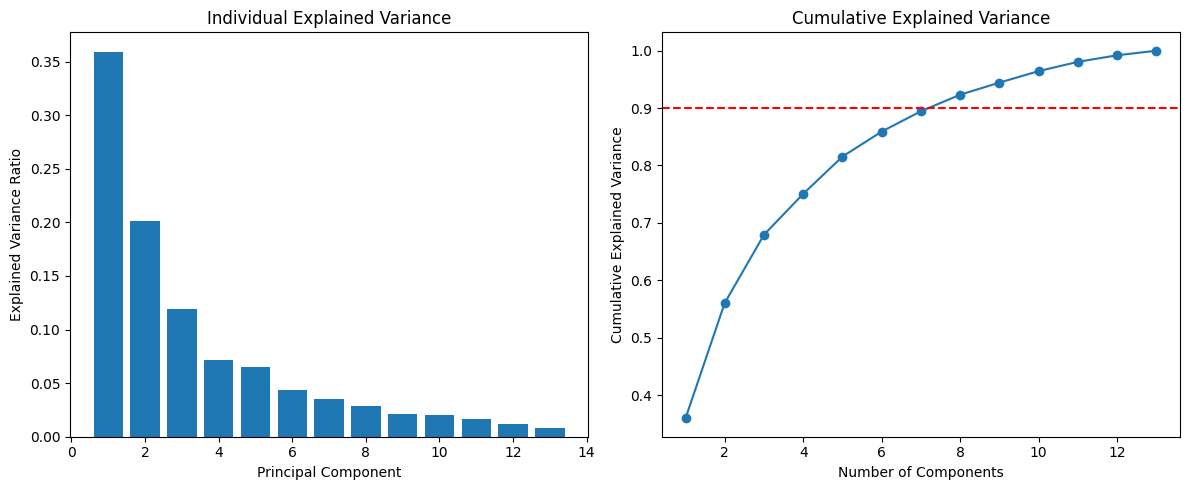

Components needed for 90% variance: 8


In [3]:
# B
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

pca = PCA(n_components=13)

X_train_pca = pca.fit_transform(X_train_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.bar(range(1, 14), explained_variance)
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Individual Explained Variance')

plt.subplot(1, 2, 2)
plt.plot(range(1, 14), cumulative_variance, marker='o')
plt.axhline(y=0.90, color='red', linestyle='--')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')

plt.tight_layout()
plt.show()

n_components = np.argmax(cumulative_variance >= 0.90) + 1

print("Components needed for 90% variance:", n_components)

In [4]:
# C
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

pca2 = PCA(n_components=2)

X_train_pca2 = pca2.fit_transform(X_train_scaled)
X_test_pca2 = pca2.transform(X_test_scaled)

lr_pca = LogisticRegression(max_iter=1000)
lr_pca.fit(X_train_pca2, y_train)

y_train_pred_pca = lr_pca.predict(X_train_pca2)
y_test_pred_pca = lr_pca.predict(X_test_pca2)

print("PCA Training Accuracy:", accuracy_score(y_train, y_train_pred_pca))
print("PCA Testing Accuracy:", accuracy_score(y_test, y_test_pred_pca))

PCA Training Accuracy: 0.9516129032258065
PCA Testing Accuracy: 0.9814814814814815


LDA Training Accuracy: 1.0
LDA Testing Accuracy: 0.9629629629629629


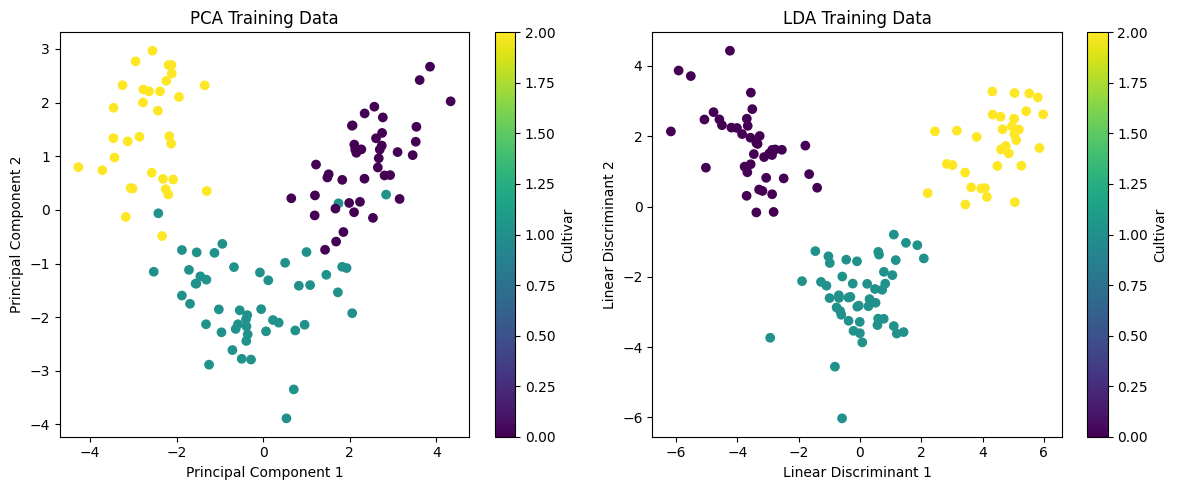

In [5]:
# D 
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2)

X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

lr_lda = LogisticRegression(max_iter=1000)
lr_lda.fit(X_train_lda, y_train)

y_train_pred_lda = lr_lda.predict(X_train_lda)
y_test_pred_lda = lr_lda.predict(X_test_lda)

print("LDA Training Accuracy:", accuracy_score(y_train, y_train_pred_lda))
print("LDA Testing Accuracy:", accuracy_score(y_test, y_test_pred_lda))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_train_pca2[:, 0], X_train_pca2[:, 1],
            c=y_train, cmap='viridis')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Training Data')
plt.colorbar(label='Cultivar')

plt.subplot(1, 2, 2)
plt.scatter(X_train_lda[:, 0], X_train_lda[:, 1],
            c=y_train, cmap='viridis')
plt.xlabel('Linear Discriminant 1')
plt.ylabel('Linear Discriminant 2')
plt.title('LDA Training Data')
plt.colorbar(label='Cultivar')

plt.tight_layout()
plt.show()

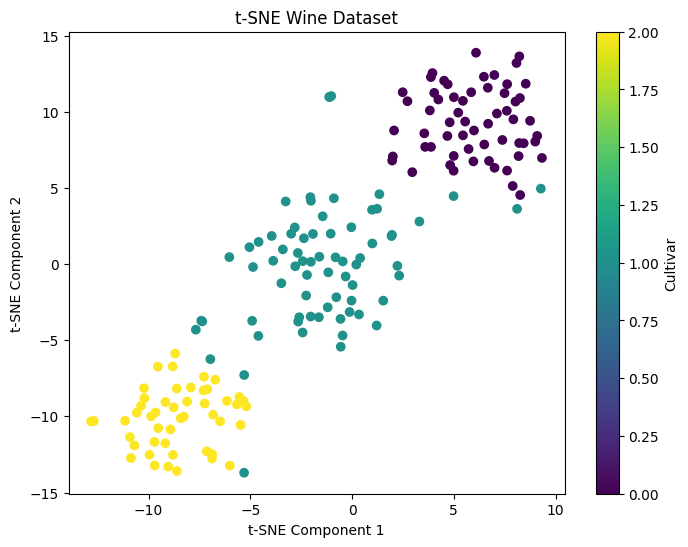

In [6]:
# E
from sklearn.manifold import TSNE

X_scaled = scaler.transform(X)

tsne = TSNE(n_components=2, perplexity=30, random_state=1)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(X_tsne[:, 0], X_tsne[:, 1],
            c=y, cmap='viridis')

plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('t-SNE Wine Dataset')
plt.colorbar(label='Cultivar')

plt.show()

# F
In 2–3 sentences, compare the three methods based on your results. Which would you use for a classifier, and which only for visualization? Why?

 - PCA explained the most variance with 8 components to reach 90%.
 - LDA got the highest training accuracy with 100% and 96.3% test accuracy.
 - t-SNE was useful for visualizing clusters and identifying patterns.
 - I would use LDA for classification because it considers class labels. 


## Exercise 4 (9 points)

A hospital builds a classifier to detect a rare disease that affects 5% of patients. The model achieves 95% accuracy on a test set that has the same 5% prevalence.

**(a)** What is the *null accuracy* in this problem? Explain why a 95% accuracy might say nothing about the usefulness of the model.

**(b)** Name two metrics (computed from the confusion matrix) that would be more informative here, give their formulas, and explain what each tells you about the rare class.

**(c)** A dataset has $n = 1000$ observations, of which 50 are positive. Compute the "balanced" class weights $w_j = \frac{n}{k\, n_j}$ for each class and explain what they accomplish.

*Write your answer here.*
 - A. The null accuracy is 95% because 95 out of 100 patients do not have the disease. The model could achieve 95% simply by predicting that every patient is healthy, without identifying anyone with the disease. So, this could mean the model is not very useful
 - B. Recall and Precision. Recall measures the percentage of actual positive cases that the model correctly identifies. This is important for rare disease cases because you want to minimize false negatives. Precision measures the percentage of patients predicted to have the disease who actually have it. Helps to determine the reliability of the models positive predictions.
 - C. Positive class = 1000/2(50) which equals 10 and Negative class = 1000/2(950) which equals .526. The balanced class weights give more importance to the minority positive class and less importance to the majority negative class. 

## Exercise 5 (5 points)

A fraud-detection team assigns a cost of $C_{FP} = 2$ to every false positive (an unnecessary review) and $C_{FN} = 10$ to every false negative (a missed fraud). Assuming the model produces well-calibrated probabilities, which statement is **TRUE**?

**A.** The cost-optimal cutoff is $c^* = C_{FN}/(C_{FP}+C_{FN}) \approx 0.83$, so only very confident predictions should be flagged as fraud.

**B.** The cost-optimal cutoff is $c^* = C_{FP}/(C_{FP}+C_{FN}) \approx 0.17$, so transactions with predicted fraud probability above about 0.17 should be flagged.

**C.** The cost-optimal cutoff is 0.5 regardless of the costs, because the costs only matter during training.

**D.** ROC-AUC will change if we move the cutoff from 0.5 to 0.17, so ROC-AUC should be used to pick the cutoff.

Select one answer and justify it in one or two sentences.

*Write your answer here.*
 - I think the True statement is B, because false negatives are five times more costly than false positives, the model should use a lower cutoff. Any probability above .17 should be flagged and reviewed.

## Exercise 6: (30 points)

In this exercise you will study classification on imbalanced data. Generate the data with:

```python
from sklearn.datasets import make_classification
X, y = make_classification(n_samples = 5000, n_features = 10, n_informative = 5,
                           weights = [0.92, 0.08], flip_y = 0.03, class_sep = 0.8,
                           random_state = 1)
```

Treat class 1 as the positive (event) class.

**(a)** Split the data into training (60%), validation (20%) and test (20%) sets using stratified sampling (`random_state = 1`). Report the proportion of positives in each set and the *null accuracy* on the test set.

**(b)** Fit a `RandomForestClassifier(n_estimators = 200, max_depth = 5, random_state = 1)` on the training set. On the test set (default cutoff 0.5) report accuracy, recall, precision, F1, balanced accuracy, ROC-AUC and PR-AUC.

**(c)** Refit the random forest with `class_weight = 'balanced'`. Report the same metrics on the test set (cutoff 0.5) and compare with (b).

**(d)** Suppose $C_{FP} = 1$ and $C_{FN} = 5$. Using the **baseline** model from (b), compute the total cost on the validation set for cutoffs from 0.01 to 0.99 (step 0.01), plot total cost vs. cutoff, and choose the cutoff with the smallest cost. Also compute the theoretical cutoff $c^* = C_{FP}/(C_{FP}+C_{FN})$.

**(e)** Apply the chosen cutoff to the test set and report the confusion matrix and total test cost. Compare it with the total cost of (i) the baseline model at cutoff 0.5, (ii) the "flag nobody" strategy and (iii) the "flag everybody" strategy.

**(f)** In 3–4 sentences, summarize what you learned: which approach (class weights vs. moving the cutoff) worked better in terms of cost, and why accuracy alone would have been misleading.

In [7]:
# A 
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
import numpy as np

X, y = make_classification(
    n_samples=5000, n_features=10, n_informative=5,
    weights=[0.92, 0.08], flip_y=0.03, class_sep=0.8,
    random_state=1
)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=1
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=1
)

print("Training positive proportion:", np.mean(y_train))
print("Validation positive proportion:", np.mean(y_val))
print("Test positive proportion:", np.mean(y_test))

null_accuracy = max(np.mean(y_test == 0), np.mean(y_test == 1))

print("Test Null Accuracy:", null_accuracy)

Training positive proportion: 0.091
Validation positive proportion: 0.091
Test positive proportion: 0.091
Test Null Accuracy: 0.909


In [8]:
# B
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score
from sklearn.metrics import precision_score, f1_score
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import roc_auc_score, average_precision_score

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=1
)

rf.fit(X_train, y_train)

y_prob = rf.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

Accuracy: 0.937
Recall: 0.3076923076923077
Precision: 1.0
F1: 0.47058823529411764
Balanced Accuracy: 0.6538461538461539
ROC-AUC: 0.904906974213905
PR-AUC: 0.7783683441054746


In [9]:
# C
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=1,
    class_weight='balanced'
)

rf_balanced.fit(X_train, y_train)

y_prob_balanced = rf_balanced.predict_proba(X_test)[:, 1]
y_pred_balanced = (y_prob_balanced >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("Recall:", recall_score(y_test, y_pred_balanced))
print("Precision:", precision_score(y_test, y_pred_balanced))
print("F1:", f1_score(y_test, y_pred_balanced))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred_balanced))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_balanced))
print("PR-AUC:", average_precision_score(y_test, y_prob_balanced))

Accuracy: 0.913
Recall: 0.7582417582417582
Precision: 0.5149253731343284
F1: 0.6133333333333333
Balanced Accuracy: 0.8433673037633433
ROC-AUC: 0.8924551795838925
PR-AUC: 0.7430940844393167


Best Cutoff: 0.14
Minimum Validation Cost: 164


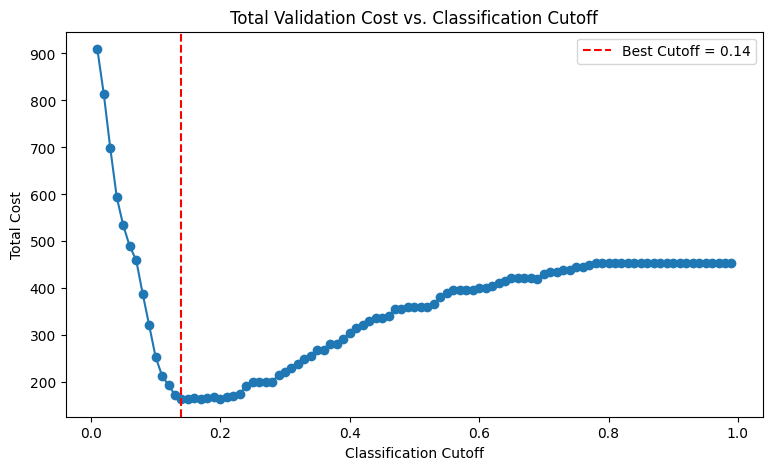

In [10]:
# D
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

y_val_prob = rf.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.01, 1.00, 0.01)
total_costs = []

for cutoff in thresholds:
    y_val_pred = (y_val_prob >= cutoff).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred
    ).ravel()

    cost = fp * 1 + fn * 5

    total_costs.append(cost)

best_cutoff = thresholds[np.argmin(total_costs)]
best_cost = min(total_costs)

print("Best Cutoff:", best_cutoff)
print("Minimum Validation Cost:", best_cost)

plt.figure(figsize=(9, 5))
plt.plot(thresholds, total_costs, marker='o')
plt.axvline(best_cutoff, color='red', linestyle='--',
            label=f'Best Cutoff = {best_cutoff:.2f}')

plt.xlabel("Classification Cutoff")
plt.ylabel("Total Cost")
plt.title("Total Validation Cost vs. Classification Cutoff")
plt.legend()
plt.show()

In [11]:
# E
y_test_pred_best = (y_prob >= best_cutoff).astype(int)

cm = confusion_matrix(y_test, y_test_pred_best)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

best_test_cost = fp * 1 + fn * 5

print("Total Test Cost:", best_test_cost)

Confusion Matrix:
[[855  54]
 [ 20  71]]
Total Test Cost: 154


# F
 - In 3–4 sentences, summarize what you learned: which approach (class weights vs. moving the cutoff) worked better in terms of cost, and why accuracy alone would have been misleading.

 - The cutoff works better for total cost using balanced class weights. The optimized cutoff of .14 reduced the cost to 154 compared to baseline cutoff of Random Forest of 315, using the .5 cutoff. Accuracy by itself was misleading becuase the baseline model had a 93.7% accuracy but only identified 30.8% of actual positive cases.